In [2]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

n_samples = 1200

brands = ['Maruti', 'Hyundai', 'Tata', 'Mahonda', 'Honda', 'Toyota', 'BMW']
fuel_types = ['Petrol', 'Diesel', 'CNG', 'EV']
transmissions = ['Manual', 'Automatic']
owner_types = ['First', 'Second', 'Third']

data = {
    'Brand': np.random.choice(brands, n_samples, p=[0.30, 0.25, 0.15, 0.10, 0.10, 0.05, 0.05]),
    'Fuel_Type': np.random.choice(fuel_types, n_samples, p=[0.50, 0.35, 0.10, 0.05]),
    'Transmission': np.random.choice(transmissions, n_samples, p=[0.75, 0.25]),
    'Owner_Type': np.random.choice(owner_types, n_samples, p=[0.70, 0.20, 0.10]),
    'Vehicle_Age': np.random.randint(1, 12, n_samples),
    'Kilometers_Driven': np.random.randint(5000, 150000, n_samples),
    'Engine_Displacement': np.random.choice([1000, 1200, 1500, 2000, 2500], n_samples, p=[0.3, 0.4, 0.2, 0.08, 0.02])
}

df = pd.DataFrame(data)

# Realistic Price Calculation Formula (in Lakh ₹) with some noise
base_price = 10.0
df['Resale_Price'] = (
    base_price
    - (df['Vehicle_Age'] * 0.7)
    - (df['Kilometers_Driven'] * 0.00003)
    + (df['Engine_Displacement'] * 0.002)
    + np.where(df['Transmission'] == 'Automatic', 1.5, 0)
    + np.where(df['Brand'] == 'Toyota', 2.0, 0)
    + np.where(df['Brand'] == 'BMW', 8.0, 0)
    + np.random.normal(0, 0.8, n_samples)
)

# Clip prices to realistic minimums
df['Resale_Price'] = np.round(df['Resale_Price'].clip(1.5, 45.0), 2)

# Save to CSV
df.to_csv('used_cars_dataset.csv', index=False)
print("Dataset 'used_cars_dataset.csv' generated successfully with 1,200 records!")

Dataset 'used_cars_dataset.csv' generated successfully with 1,200 records!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Load Data
df = pd.read_csv('used_cars_dataset.csv')
print("Dataset shape:", df.shape)

# 2. Data Preprocessing Setup
X = df.drop(columns=['Resale_Price'])
y = df['Resale_Price']

categorical_features = ['Brand', 'Fuel_Type', 'Transmission', 'Owner_Type']
numerical_features = ['Vehicle_Age', 'Kilometers_Driven', 'Engine_Displacement']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ]
)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Preprocessing setup completed successfully!")

Dataset shape: (1200, 8)
Preprocessing setup completed successfully!


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Define Models inside Pipelines combining Preprocessing and Modeling
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 2. Train Models
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# 3. Predictions
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

# 4. Evaluation Function
def evaluate_model(true, pred, model_name):
    mae = mean_absolute_error(true, pred)
    mse = mean_squared_error(true, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(true, pred)

    print(f"=== {model_name} Performance ===")
    print(f"Mean Absolute Error (MAE) : {mae:.4f} Lakh ₹")
    print(f"Mean Squared Error (MSE)  : {mse:.4f}")
    print(f"Root Mean Squared Error   : {rmse:.4f} Lakh ₹")
    print(f"R2 Score                  : {r2:.4f}\n")

evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_rf, "Random Forest Regressor")

# 5. Live Prediction Example for a New Car
sample_car = pd.DataFrame([{
    'Brand': 'Maruti',
    'Fuel_Type': 'Petrol',
    'Transmission': 'Manual',
    'Owner_Type': 'First',
    'Vehicle_Age': 3,
    'Kilometers_Driven': 25000,
    'Engine_Displacement': 1200
}])

predicted_price_rf = rf_pipeline.predict(sample_car)[0]
final_price = round(predicted_price_rf, 2)
print(f"Predicted Market Price using Random Forest: ₹ {final_price} Lakhs")

=== Linear Regression Performance ===
Mean Absolute Error (MAE) : 0.6512 Lakh ₹
Mean Squared Error (MSE)  : 0.6381
Root Mean Squared Error   : 0.7988 Lakh ₹
R2 Score                  : 0.9404

=== Random Forest Regressor Performance ===
Mean Absolute Error (MAE) : 1.2862 Lakh ₹
Mean Squared Error (MSE)  : 4.3800
Root Mean Squared Error   : 2.0928 Lakh ₹
R2 Score                  : 0.5907

Predicted Market Price using Random Forest: ₹ 9.34 Lakhs


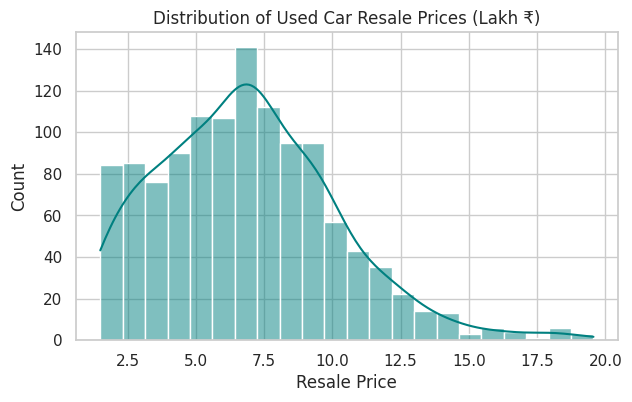

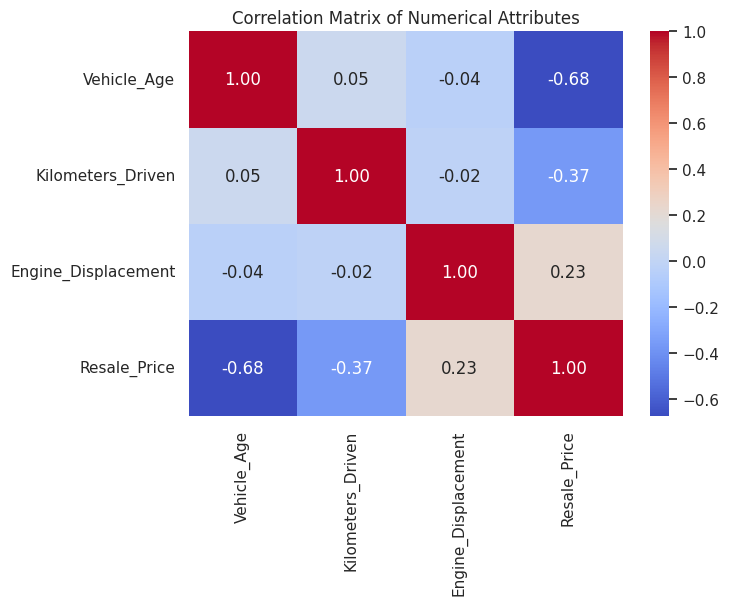

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Figure 1: Distribution of Resale Prices
plt.figure(figsize=(7, 4))
sns.histplot(df['Resale_Price'], kde=True, color='teal')
plt.title('Distribution of Used Car Resale Prices (Lakh ₹)')
plt.xlabel('Resale Price')
plt.ylabel('Count')
plt.show()

# Figure 2: Correlation Heatmap
plt.figure(figsize=(7, 5))
numeric_cols = ['Vehicle_Age', 'Kilometers_Driven', 'Engine_Displacement', 'Resale_Price']
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Attributes')
plt.show()